We first consider the case of when we have a finite number of time steps $T$. We take that our knowledge about Bernoulli buttons is given by a Beta distribution on button success probability $\theta$

$$
P(\theta|\alpha, \beta) = \frac{\theta^{\alpha-1} (1-\theta)^{\beta-1}}{B(\alpha,\beta)}.
$$

We suppose that when we move to a new button we start with a flat prior $\alpha = 1$, $\beta = 1$. For simplicity we take that in case of succes we get a reward $1$ from pressing a button, in case of fail we get no reward.

We model the problem as a Markov Decision Process, thus we search for an optimal policy $\pi(s)$ that maximizes the expected reward

$$
V(s, T) = \mathrm{E}\left[\sum_{t = 1}^T r_{a^\pi} (s_t^{\pi}) \right].
$$

We solve this problem via dynamical programming. The formal solution can be written as

$$
V(s, T) = \max_{a\in A}\left(r_a (s) + \sum_{s'\in S} p_a (s, s') V(s', T-1)\right),
$$

and $V(s, 0) = 0$. Our space of states $S$ consists of our knowledge about the current button we are pressing, so it can be described with a pair $(\alpha, \beta)$ corresponding to a Beta distribution. Our space of actions consists of either pressing the current button and moving to one of the outcomes $(\alpha+1, \beta)$ or $(\alpha, \beta+1)$ with probabilities $\alpha/(\alpha + \beta)$ and $\beta/(\alpha + \beta)$ respectively, or moving to the next button and pressing it thus arriving at one of the outcomes $(2, 1)$ or $(1, 2)$ with a probability $1/2$. Labeling the expected reward from a button with a prior knowledge $(\alpha, \beta)$ and the remaining number of steps $T$ as $V(\alpha, \beta, T)$ we get the following recurrence relation

$$
V(\alpha, \beta, T) = \max \left\{
\begin{matrix}
\frac{\alpha}{\alpha + \beta} + \frac{\alpha}{\alpha + \beta} V(\alpha+1, \beta, T-1) + \frac{\beta}{\alpha + \beta} V(\alpha, \beta+1, T-1)\\
\frac{1}{2} + \frac{1}{2} V(2, 1, T-1) + \frac{1}{2} V(1, 2, T-1)
\end{matrix}\right.,
$$

and $V(\alpha, \beta, 0) = 0$. We also note that according to this definition 

$$
V(1, 1, T) = \frac{1}{2} + \frac{1}{2} V(2, 1, T-1) + \frac{1}{2} V(1, 2, T-1).
$$

The optimal policy thus corresponds to comparing

$$
\frac{\alpha}{\alpha + \beta} + \frac{\alpha}{\alpha + \beta} V(\alpha+1, \beta, T-1) + \frac{\beta}{\alpha + \beta} V(\alpha, \beta+1, T-1),
$$ 

to $V(1, 1, T)$ and moving to the next button if the latter is greater. We can evaluate the expected reward expression numerically recursively for any $T$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def expected_reward_table(max_ab, time):
    size = max_ab+time
    val = np.zeros((time, max_ab, max_ab))

    arr = np.zeros((size, size))
    for i in range(size):
        for j in range(size):
            arr[i, j] = (i+1.)/(i+j+2.)
            
    val[0] = arr[:max_ab, :max_ab]
    for t in range(time-1):
        move_val = 0.5 + 0.5*(arr[1, 0] + arr[0, 1])
        for i in range(size - t - 1):
            for j in range(size - t - 1):
                stay_val = (i+1)/(i+j+2) + (i+1)/(i+j+2)*arr[i+1,j] + (j+1)/(i+j+2)*arr[i,j+1]
                arr[i,j] = max(move_val, stay_val)
        val[t+1] = arr[:max_ab, :max_ab]
        
    return val

In [2]:
val = expected_reward_table(10, 250)

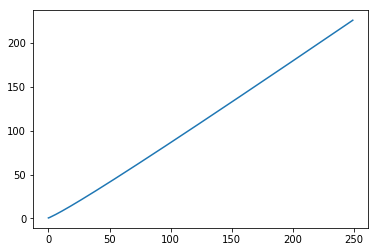

In [3]:
plt.plot(val[:,0,0])

In [4]:
val[:,5,1]-val[:,0,0]

array([2.50000000e-01, 5.00000000e-01, 5.83333333e-01, 6.66666667e-01,
       7.22222222e-01, 7.64898990e-01, 7.93476431e-01, 8.14202927e-01,
       8.29977353e-01, 8.39908741e-01, 8.43514470e-01, 8.43509694e-01,
       8.43262340e-01, 8.41053263e-01, 8.34417200e-01, 8.27157583e-01,
       8.17010507e-01, 8.04437215e-01, 7.93631494e-01, 7.86334781e-01,
       7.78120447e-01, 7.69282680e-01, 7.59655463e-01, 7.49080524e-01,
       7.39564975e-01, 7.30028783e-01, 7.19819976e-01, 7.09268479e-01,
       6.98029081e-01, 6.87555833e-01, 6.76827996e-01, 6.67516436e-01,
       6.59140963e-01, 6.50811690e-01, 6.42657914e-01, 6.34642370e-01,
       6.26292911e-01, 6.17677238e-01, 6.09117269e-01, 6.00368741e-01,
       5.91396048e-01, 5.83127214e-01, 5.75029909e-01, 5.66729432e-01,
       5.58180760e-01, 5.49537664e-01, 5.40969911e-01, 5.33274779e-01,
       5.25938241e-01, 5.18698858e-01, 5.11471465e-01, 5.04442806e-01,
       4.97484846e-01, 4.90473157e-01, 4.83480548e-01, 4.76561138e-01,
      

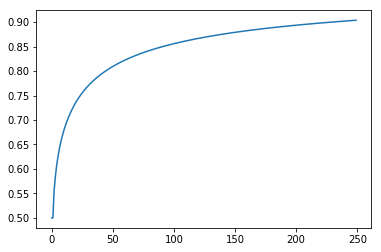

In [5]:
val_avg = np.copy(val[:,0,0])
val_avg = val_avg/np.arange(1,len(val_avg)+1)

plt.plot(val_avg)

In [9]:
print(val[99])

[[85.5347733  85.5347733  85.5347733  85.5347733  85.5347733  85.5347733
  85.5347733  85.5347733  85.5347733  85.5347733 ]
 [86.3691686  85.5347733  85.5347733  85.5347733  85.5347733  85.5347733
  85.5347733  85.5347733  85.5347733  85.5347733 ]
 [87.16354061 85.5347733  85.5347733  85.5347733  85.5347733  85.5347733
  85.5347733  85.5347733  85.5347733  85.5347733 ]
 [87.93204957 85.5347733  85.5347733  85.5347733  85.5347733  85.5347733
  85.5347733  85.5347733  85.5347733  85.5347733 ]
 [88.6817952  85.5347733  85.5347733  85.5347733  85.5347733  85.5347733
  85.5347733  85.5347733  85.5347733  85.5347733 ]
 [89.41707357 85.78234335 85.5347733  85.5347733  85.5347733  85.5347733
  85.5347733  85.5347733  85.5347733  85.5347733 ]
 [90.09959058 86.08236597 85.5347733  85.5347733  85.5347733  85.5347733
  85.5347733  85.5347733  85.5347733  85.5347733 ]
 [90.73048681 86.41187643 85.5347733  85.5347733  85.5347733  85.5347733
  85.5347733  85.5347733  85.5347733  85.5347733 ]
 [91.313